# Modélisation Images — LeNet

L'objectif de ce notebook est de concevoir un premier modèle de classification d'images avec une architecture **LeNet**. C'est un CNN simple qui nous permet de mesurer la contribution des images seules à la prédiction, avant de passer au transfer learning (VGG16, notebook 6.0).

Nos ressources de calcul étant limitées sur Kaggle (GPU T4 x2, sessions de 12h), nous allons :

1. Tester l'impact de la **taille d'image** (128px vs 256px)
2. Tester l'impact du **volume de données** (25% vs dataset complet)
3. Conclure sur la pertinence de LeNet pour ce problème à 27 classes

| Modèle | Image | Data | Résultat |
|--------|-------|------|----------|
| 111    | 128px | 25%  | F1=0.2039 |
| 112    | 256px | 25%  | F1=0.1179 |
| 113    | 256px | 100% | Interrompu (val_f1=0.2065 ep.4) |

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/X_train_pre.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/camembert_training_history.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/images_analysis.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/lang.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/translation.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train_clean.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/label_mapping.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_train.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/df_val.csv
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/tokenizer.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/tokenizer_config.json
/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed/vgg16_best.pth
/kaggle/input/datasets/tarikouhsine/raku

KeyboardInterrupt: 

### CELLULE 1 — Setup & Imports

In [2]:
import os, sys, zipfile, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Dense, Dropout, Flatten,
                                     Conv2D, MaxPooling2D, AveragePooling2D)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import Callback, EarlyStopping, LearningRateScheduler
from tensorflow.keras import backend as K
import keras.saving
from keras.utils import to_categorical
from keras.models import load_model

# ── Chemins Kaggle ───────────────────────────────────────────────────────────
INPUT_DIR  = Path('/kaggle/input/datasets/tarikouhsine/rakuten-preprocessed')
IMAGE_DIR  = INPUT_DIR / 'images' / 'images' / 'image_train'
WORK_DIR   = Path('/kaggle/working')
OUTPUT_DIR = WORK_DIR / 'modeling-lenet'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random_state = 42
start_lr     = 0.001

print(f"TensorFlow : {tf.__version__}")
print(f"GPU dispo  : {tf.config.list_physical_devices('GPU')}")
print(f"Image dir  : {IMAGE_DIR.exists()} ({len(list(IMAGE_DIR.glob('*.jpg'))):,} images)")

2026-05-19 12:42:18.487508: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779194538.739493      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779194538.808410      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779194539.352822      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779194539.352893      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779194539.352897      57 computation_placer.cc:177] computation placer alr

TensorFlow : 2.19.0
GPU dispo  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Image dir  : True (84,916 images)


## CELLULE 2 — Fonctions de reporting

In [4]:
output_dir = str(OUTPUT_DIR)

def create_reporting_df(save=True):
    reporting_df = pd.DataFrame([{
        "model_id"                    : int(0),
        "model_name"                  : "Exemple",
        "dataset_resampled"           : False,
        "image_dataset_zoomed"        : False,
        "train_size"                  : int(0),
        "image_size"                  : int(128),
        "image_color_rgb"             : True,
        "batch_size"                  : int(32),
        "image_data_generator_params" : {},
        "start_lr"                    : 0.001,
        "last_lr"                     : 0.001,
        "optimizer"                   : "adam",
        "target_epochs"               : int(10),
        "last_epoch"                  : int(0),
        "fit_complete"                : False,
        "f1_score"                    : 0.0,
        "val_f1_score"                : 0.0,
        "test_f1_score"               : 0.0,
        "accuracy"                    : 0.0,
        "val_accuracy"                : 0.0,
        "test_accuracy"               : 0.0,
        "loss"                        : 0.0,
        "val_loss"                    : 0.0,
        "remarks"                     : "",
    }])
    reporting_df.set_index("model_id", inplace=True)
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")
    return reporting_df

def load_reporting_df():
    return pd.read_csv(output_dir + "/model_reporting.csv", index_col="model_id")

def add_reporting_line(model_id, model_name, save=True):
    reporting_df.loc[int(model_id), "model_name"] = str(model_name)
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")

def update_reporting_line(model_id, d={}, save=True):
    for key in d.keys():
        reporting_df.at[int(model_id), str(key)] = d.get(key)
    if save:
        reporting_df.to_csv(output_dir + "/model_reporting.csv")

def get_reporting_value(model_id, key, default=None):
    try:
        value = reporting_df.at[model_id, key]
        if pd.isna(value):
            value = None
    except KeyError:
        value = None
    if value is None and default is not None:
        value = default
    return value

print("✅ Fonctions reporting prêtes")

✅ Fonctions reporting prêtes


## CELLULE 3 — Fonctions modèle, sauvegarde, évaluation

In [13]:
# ── Architecture LeNet ───────────────────────────────────────────────────────
def build_model(input_shape):
    model = Sequential([
        Conv2D(6,  (5, 5), activation='relu', input_shape=input_shape),
        AveragePooling2D(pool_size=(2, 2)),
        Conv2D(16, (5, 5), activation='relu'),
        AveragePooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(120, activation='relu'),
        Dense(84,  activation='relu'),
        Dense(27,  activation='softmax'),
    ])
    return model

# ── Métrique F1 Keras ────────────────────────────────────────────────────────
def f1_score_sklearn(y_true, y_pred):
    y_true_classes = np.argmax(y_true, axis=1)
    y_pred_classes = np.argmax(y_pred, axis=1)
    return f1_score(y_true_classes, y_pred_classes, average='weighted')

@keras.saving.register_keras_serializable(name='w_f1_score')
# tf.numpy_function + set_shape([]) → scalaire explicite
def w_f1_score(y_true, y_pred):
    score = tf.numpy_function(f1_score_sklearn, [y_true, y_pred], tf.float32)
    score.set_shape([])
    return score

# ── Sauvegarde / chargement modèle ───────────────────────────────────────────
def save_model_fn(model_id, model):
    path = output_dir + f"/model-{model_id}.keras"
    model.save(path)
    print(f"   💾 Modèle {model_id} sauvegardé → {path}")

def load_saved_model(model_id):
    path = Path(output_dir) / f"model-{model_id}.keras"
    if path.exists():
        print(f"   📂 Chargement modèle {model_id}")
        return load_model(path)
    return None

# ── Historique d'entraînement ─────────────────────────────────────────────────
def save_history(model_id, history):
    path = output_dir + f"/history_{model_id}.pkl"
    with open(path, "wb") as f:
        pickle.dump(history, f)

def load_history(model_id):
    path = Path(output_dir) / f"history_{model_id}.pkl"
    if path.exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

def concat_histories(prev, curr):
    return {k: np.concatenate((prev[k], curr[k]), axis=0) for k in curr}

def get_full_history(model_id, training_history):
    if training_history is None:
        return load_history(model_id)
    prev = load_history(model_id)
    if prev is not None:
        return concat_histories(prev, training_history.history)
    return training_history.history

# ── Callback LogBest ──────────────────────────────────────────────────────────
class LogBest(Callback):
    def __init__(self, model_id):
        super().__init__()
        self.model_id = model_id

    def on_epoch_end(self, epoch, logs=None):
        update_reporting_line(self.model_id, {
            'last_epoch': epoch + 1,
            'last_lr'   : float(K.get_value(self.model.optimizer.learning_rate)),
        })
        if float(logs['val_w_f1_score']) <= float(
                get_reporting_value(self.model_id, "val_f1_score", 0.0)):
            return
        print(f"\n   ✅ Meilleur modèle — val_f1={float(logs['val_w_f1_score']):.4f}")
        update_reporting_line(self.model_id, {
            "f1_score"    : logs['w_f1_score'],
            "val_f1_score": logs['val_w_f1_score'],
            "accuracy"    : logs['accuracy'],
            "val_accuracy": logs['val_accuracy'],
            "loss"        : logs['loss'],
            "val_loss"    : logs['val_loss'],
        })
        save_model_fn(self.model_id, self.model)

# ── EarlyStopping ─────────────────────────────────────────────────────────────
early_stopping = EarlyStopping(
    monitor='val_w_f1_score', mode="max",
    patience=5, min_delta=1e-2
)

# ── Visualisation ──────────────────────────────────────────────────────────────
CODE2LABEL = {
    10:'Livre occ.', 40:'Jeu vidéo', 50:'Access.Console',
    60:'Console', 1140:'Figurine', 1160:'Carte Coll.',
    1180:'Jeu Plateau', 1280:'Jouet enf.', 1281:'Jeu société',
    1300:'Jouet tech', 1301:'Chaussettes', 1302:'Jeu ext.',
    1320:'Bébé', 1560:'Mobilier int.', 1920:'Chambre',
    1940:'Cuisine', 2060:'Déco int.', 2220:'Animal',
    2280:'Revues', 2403:'Magazines', 2462:'Jeu occ.',
    2522:'Bureautique', 2582:'Mobilier ext.', 2583:'Piscine',
    2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}

def plot_training_history(history):
    x = range(1, len(history['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(x, history['val_accuracy'],    label="val_accuracy")
    axes[0].plot(x, history['accuracy'],        label="accuracy")
    axes[0].plot(x, history['val_w_f1_score'],  label="val_f1_score")
    axes[0].plot(x, history['w_f1_score'],      label="f1_score")
    axes[0].set_title("Accuracy / F1 par époque")
    axes[0].set_xlabel("Époque")
    axes[0].legend()
    axes[1].plot(x, history['val_loss'], label="val_loss")
    axes[1].plot(x, history['loss'],     label="loss")
    axes[1].set_title("Loss par époque")
    axes[1].set_xlabel("Époque")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(cm, classes_keras):
    labels = [f"{c}: {CODE2LABEL.get(int(c), c)}" for c in classes_keras]
    plt.figure(figsize=(16, 10))
    sns.set(font_scale=0.7)
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.xlabel('Prédit')
    plt.ylabel('Réel')
    plt.title('Matrice de confusion')
    plt.tight_layout()
    plt.show()

print("✅ Fonctions modèle prêtes")

✅ Fonctions modèle prêtes


In [19]:
# ── Architecture LeNet ───────────────────────────────────────────────────────
def build_model(input_shape):
    model = Sequential([
        Conv2D(6,  (5, 5), activation='relu', input_shape=input_shape),
        AveragePooling2D(pool_size=(2, 2)),
        Conv2D(16, (5, 5), activation='relu'),
        AveragePooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(120, activation='relu'),
        Dense(84,  activation='relu'),
        Dense(27,  activation='softmax'),
    ])
    return model

# ── Métrique F1 — pure TensorFlow, compatible XLA GPU ────────────────────────
NUM_CLASSES = 27

@keras.saving.register_keras_serializable(name='WeightedF1Score')
class WeightedF1Score(tf.keras.metrics.Metric):
    """F1-score pondéré implémenté en pure TF — compatible XLA/GPU"""

    def __init__(self, num_classes=NUM_CLASSES, name='w_f1_score', **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.tp = self.add_weight(shape=(num_classes,), initializer='zeros', name='tp')
        self.fp = self.add_weight(shape=(num_classes,), initializer='zeros', name='fp')
        self.fn = self.add_weight(shape=(num_classes,), initializer='zeros', name='fn')
        self.support = self.add_weight(shape=(num_classes,), initializer='zeros', name='support')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true_cls = tf.argmax(y_true, axis=1)
        y_pred_cls = tf.argmax(y_pred, axis=1)
        y_true_oh  = tf.one_hot(y_true_cls, self.num_classes)
        y_pred_oh  = tf.one_hot(y_pred_cls, self.num_classes)
        self.tp.assign_add(tf.reduce_sum(y_true_oh * y_pred_oh,        axis=0))
        self.fp.assign_add(tf.reduce_sum((1 - y_true_oh) * y_pred_oh,  axis=0))
        self.fn.assign_add(tf.reduce_sum(y_true_oh * (1 - y_pred_oh),  axis=0))
        self.support.assign_add(tf.reduce_sum(y_true_oh,               axis=0))

    def result(self):
        eps       = tf.keras.backend.epsilon()
        precision = self.tp / (self.tp + self.fp + eps)
        recall    = self.tp / (self.tp + self.fn + eps)
        f1        = 2 * precision * recall / (precision + recall + eps)
        weights   = self.support / (tf.reduce_sum(self.support) + eps)
        return tf.reduce_sum(f1 * weights)

    def reset_state(self):
        zeros = tf.zeros(self.num_classes)
        self.tp.assign(zeros)
        self.fp.assign(zeros)
        self.fn.assign(zeros)
        self.support.assign(zeros)

    def get_config(self):
        config = super().get_config()
        config.update({"num_classes": self.num_classes})
        return config

# Instance globale réutilisée dans tous les modèles
w_f1_score = WeightedF1Score(num_classes=NUM_CLASSES)

# ── Sauvegarde / chargement modèle ───────────────────────────────────────────
def save_model_fn(model_id, model):
    path = output_dir + f"/model-{model_id}.keras"
    model.save(path)
    print(f"   💾 Modèle {model_id} sauvegardé → {path}")

def load_saved_model(model_id):
    path = Path(output_dir) / f"model-{model_id}.keras"
    if path.exists():
        print(f"   📂 Chargement modèle {model_id}")
        return load_model(path, custom_objects={'WeightedF1Score': WeightedF1Score})
    return None

# ── Historique ────────────────────────────────────────────────────────────────
def save_history(model_id, history):
    with open(output_dir + f"/history_{model_id}.pkl", "wb") as f:
        pickle.dump(history, f)

def load_history(model_id):
    path = Path(output_dir) / f"history_{model_id}.pkl"
    if path.exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

def concat_histories(prev, curr):
    return {k: np.concatenate((prev[k], curr[k]), axis=0) for k in curr}

def get_full_history(model_id, training_history):
    if training_history is None:
        return load_history(model_id)
    prev = load_history(model_id)
    if prev is not None:
        return concat_histories(prev, training_history.history)
    return training_history.history

# ── Callback LogBest ──────────────────────────────────────────────────────────
class LogBest(Callback):
    def __init__(self, model_id):
        super().__init__()
        self.model_id = model_id

    def on_epoch_end(self, epoch, logs=None):
        update_reporting_line(self.model_id, {
            'last_epoch': epoch + 1,
            'last_lr'   : float(K.get_value(self.model.optimizer.learning_rate)),
        })
        if float(logs['val_w_f1_score']) <= float(
                get_reporting_value(self.model_id, "val_f1_score", 0.0)):
            return
        print(f"\n   ✅ Meilleur modèle — val_f1={float(logs['val_w_f1_score']):.4f}")
        update_reporting_line(self.model_id, {
            "f1_score"    : float(logs['w_f1_score']),
            "val_f1_score": float(logs['val_w_f1_score']),
            "accuracy"    : float(logs['accuracy']),
            "val_accuracy": float(logs['val_accuracy']),
            "loss"        : float(logs['loss']),
            "val_loss"    : float(logs['val_loss']),
        })
        save_model_fn(self.model_id, self.model)

# ── EarlyStopping ─────────────────────────────────────────────────────────────
early_stopping = EarlyStopping(
    monitor='val_w_f1_score', mode="max",
    patience=5, min_delta=1e-2
)

# ── Visualisation ──────────────────────────────────────────────────────────────
CODE2LABEL = {
    10:'Livre occ.', 40:'Jeu vidéo', 50:'Access.Console',
    60:'Console', 1140:'Figurine', 1160:'Carte Coll.',
    1180:'Jeu Plateau', 1280:'Jouet enf.', 1281:'Jeu société',
    1300:'Jouet tech', 1301:'Chaussettes', 1302:'Jeu ext.',
    1320:'Bébé', 1560:'Mobilier int.', 1920:'Chambre',
    1940:'Cuisine', 2060:'Déco int.', 2220:'Animal',
    2280:'Revues', 2403:'Magazines', 2462:'Jeu occ.',
    2522:'Bureautique', 2582:'Mobilier ext.', 2583:'Piscine',
    2585:'Bricolage', 2705:'Livre neuf', 2905:'Jeu PC',
}

def plot_training_history(history):
    x = range(1, len(history['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(x, history['val_w_f1_score'], label="val_f1")
    axes[0].plot(x, history['w_f1_score'],     label="train_f1")
    axes[0].plot(x, history['val_accuracy'],   label="val_accuracy")
    axes[0].plot(x, history['accuracy'],       label="train_accuracy")
    axes[0].set_title("F1 / Accuracy par époque")
    axes[0].legend()
    axes[1].plot(x, history['val_loss'], label="val_loss")
    axes[1].plot(x, history['loss'],     label="train_loss")
    axes[1].set_title("Loss par époque")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(cm, classes_keras):
    labels = [f"{c}: {CODE2LABEL.get(int(c), c)}" for c in classes_keras]
    plt.figure(figsize=(16, 10))
    sns.set(font_scale=0.7)
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.xlabel('Prédit')
    plt.ylabel('Réel')
    plt.title('Matrice de confusion')
    plt.tight_layout()
    plt.show()

print("✅ Fonctions modèle prêtes — WeightedF1Score pure TF (compatible XLA)")
print(f"   w_f1_score = {w_f1_score.name}")

✅ Fonctions modèle prêtes — WeightedF1Score pure TF (compatible XLA)
   w_f1_score = w_f1_score


## CELLULE 4 — Chargement des données

In [20]:
df_train = pd.read_csv(INPUT_DIR / 'df_train.csv', index_col=0)
df_val   = pd.read_csv(INPUT_DIR / 'df_val.csv',   index_col=0)
df_test  = pd.read_csv(INPUT_DIR / 'df_test.csv',  index_col=0)

# Classes ordonnées
classes_keras = list(np.sort(
    np.array(df_train['prdtypecode'].unique(), dtype="str")
))

print(f"Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}")
print(f"Classes : {len(classes_keras)}")
print(f"Colonnes : {df_train.columns.tolist()}")

# Construction colonne imagefile si absente
for df in [df_train, df_val, df_test]:
    if 'imagefile' not in df.columns:
        df['imagefile'] = ('image_' + df['imageid'].astype(str) +
                           '_product_' + df['productid'].astype(str) + '.jpg')

# Vérification images
ok = sum(1 for f in df_train['imagefile'].head(20)
         if (IMAGE_DIR / f).exists())
print(f"\nVérification images (20 premières) : {ok}/20 trouvées")

Train : (109566, 8) | Val : (8492, 8) | Test : (8492, 8)
Classes : 27
Colonnes : ['productid', 'imageid', 'text_fr', 'lang', 'categorie', 'imagefile', 'text_lemmatise', 'prdtypecode']

Vérification images (20 premières) : 20/20 trouvées


## CELLULE 5 — Initialisation reporting

In [26]:
try:
    reporting_df = load_reporting_df()
    print("✅ Reporting chargé")
except FileNotFoundError:
    reporting_df = create_reporting_df()
    print("✅ Nouveau reporting créé")

display(reporting_df.head())

✅ Reporting chargé


,model_name,dataset_resampled,image_dataset_zoomed,train_size,image_size,image_color_rgb,batch_size,image_data_generator_params,start_lr,last_lr,...,fit_complete,f1_score,val_f1_score,test_f1_score,accuracy,val_accuracy,test_accuracy,loss,val_loss,remarks
model_id,,,,,,,,,,,,,,,,,,,,,
0,Exemple,False,False,0.0,128.0,True,32.0,{},0.001,0.001,...,False,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
111,LeNet 128px - dataset complet,True,True,27391.0,128.0,True,64.0,NaN,0.001,0.001,...,True,0.156775,0.19922,0.203874,0.178615,0.214134,0.221032,2.818295,2.745057,NaN


## CELLULE 6 — Générateurs d'images (configuration partagée) 

In [22]:
# Paramètres de base — modifiés selon les modèles
batch_size     = 64
target_img_size = (128, 128, 3)
color_mode     = "rgb"

train_data_generator = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=5,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_test_generator = ImageDataGenerator(rescale=1./255)

def make_generators(df_tr, df_v, df_te, img_size, bs):
    """Crée les 3 générateurs train/val/test"""
    def flow(df, gen, shuffle):
        return gen.flow_from_dataframe(
            dataframe=pd.DataFrame({
                "imagefile"  : df['imagefile'],
                "prdtypecode": df['prdtypecode'].astype("str")
            }),
            x_col="imagefile",
            y_col="prdtypecode",
            directory=str(IMAGE_DIR),
            target_size=img_size[:2],
            color_mode=color_mode,
            batch_size=bs,
            class_mode="categorical",
            classes=classes_keras,
            shuffle=shuffle
        )
    return (flow(df_tr, train_data_generator, True),
            flow(df_v,  val_test_generator,   False),
            flow(df_te, val_test_generator,   False))

print("✅ Générateurs configurés")

✅ Générateurs configurés


## CELLULE 7 — Modèle 1.1 : Dataset complet, images 128px

In [23]:
model_id    = 111
target_epochs = 10

add_reporting_line(model_id, "LeNet 128px - dataset complet")
update_reporting_line(model_id, {
    "dataset_resampled"  : True,
    "image_dataset_zoomed": True,
    "train_size"         : len(df_train),
    "image_size"         : 128,
    "batch_size"         : batch_size,
    "image_color_rgb"    : True,
    "start_lr"           : start_lr,
    "optimizer"          : "adam",
    "target_epochs"      : target_epochs,
})

# Sous-ensemble train (~25%)
target_size = int(len(df_train) * 0.25)
df_sub, _, = train_test_split(df_train, train_size=target_size,
                               random_state=random_state,
                               stratify=df_train['prdtypecode'])

train_gen, val_gen, test_gen = make_generators(
    df_sub, df_val, df_test, target_img_size, batch_size)

update_reporting_line(model_id, {"train_size": len(df_sub)})

model = load_saved_model(model_id)
if model is None:
    model = build_model(target_img_size)
    model.compile(optimizer=Adam(learning_rate=start_lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', w_f1_score])

model.summary()

Found 27391 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 124, 124, 6)    │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 62, 62, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 58, 58, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 29, 29, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 13456)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 120)            │     1,614,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 27)             │         2,295 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,630,171 (6.22 MB)

 Trainable params: 1,630,171 (6.22 MB)

 Non-trainable params: 0 (0.00 B)

## CELLULE 8 — Entraînement modèle 1.1

In [24]:
if not get_reporting_value(model_id, "fit_complete", False):
    training_history = model.fit(
        train_gen,
        validation_data=val_gen,
        steps_per_epoch=train_gen.samples // batch_size,
        validation_steps=val_gen.samples // batch_size,
        epochs=target_epochs - int(get_reporting_value(model_id, "last_epoch", 0)),
        callbacks=[LogBest(model_id), early_stopping]
    )
    update_reporting_line(model_id, {"fit_complete": True})
else:
    print("Déjà entraîné")
    training_history = None

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1779196147.364468     132 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-05-19 13:09:09.034840: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-19 13:09:09.172875: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  1/427 ━━━━━━━━━━━━━━━━━━━━ 44:24 6s/step - accuracy: 0.0156 - loss: 3.3884 - w_f1_score: 0.0011

I0000 00:00:1779196151.071699     132 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  3/427 ━━━━━━━━━━━━━━━━━━━━ 2:20 332ms/step - accuracy: 0.0278 - loss: 3.4430 - w_f1_score: 0.0052

2026-05-19 13:09:13.205399: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-19 13:09:13.343714: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


427/427 ━━━━━━━━━━━━━━━━━━━━ 0s 588ms/step - accuracy: 0.0680 - loss: 3.2411 - w_f1_score: 0.0520
   ✅ Meilleur modèle — val_f1=0.0608
   💾 Modèle 111 sauvegardé → /kaggle/working/modeling-lenet/model-111.keras
427/427 ━━━━━━━━━━━━━━━━━━━━ 310s 713ms/step - accuracy: 0.0680 - loss: 3.2409 - w_f1_score: 0.0521 - val_accuracy: 0.0942 - val_loss: 3.0952 - val_w_f1_score: 0.0608
Epoch 2/10
  1/427 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.1094 - loss: 3.1869 - w_f1_score: 0.0862

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


427/427 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.1094 - loss: 3.1869 - w_f1_score: 0.0862 - val_accuracy: 0.0947 - val_loss: 3.0976 - val_w_f1_score: 0.0603
Epoch 3/10
427/427 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.1274 - loss: 3.0272 - w_f1_score: 0.1001
   ✅ Meilleur modèle — val_f1=0.1235
   💾 Modèle 111 sauvegardé → /kaggle/working/modeling-lenet/model-111.keras
427/427 ━━━━━━━━━━━━━━━━━━━━ 214s 502ms/step - accuracy: 0.1274 - loss: 3.0271 - w_f1_score: 0.1001 - val_accuracy: 0.1407 - val_loss: 2.9221 - val_w_f1_score: 0.1235
Epoch 4/10
427/427 ━━━━━━━━━━━━━━━━━━━━ 29s 67ms/step - accuracy: 0.1719 - loss: 3.0552 - w_f1_score: 0.1283 - val_accuracy: 0.1364 - val_loss: 2.9312 - val_w_f1_score: 0.1167
Epoch 5/10
427/427 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step - accuracy: 0.1493 - loss: 2.9328 - w_f1_score: 0.1231
   ✅ Meilleur modèle — val_f1=0.1435
   💾 Modèle 111 sauvegardé → /kaggle/working/modeling-lenet/model-111.keras
427/427 ━━━━━━━━━━━━━━━━━━━━ 29s 68ms/step - acc

## CELLULE 9 — Évaluation modèle 1.1

   📂 Chargement modèle 111
133/133 ━━━━━━━━━━━━━━━━━━━━ 77s 577ms/step
F1 Test  : 0.2039
Accuracy : 0.2210


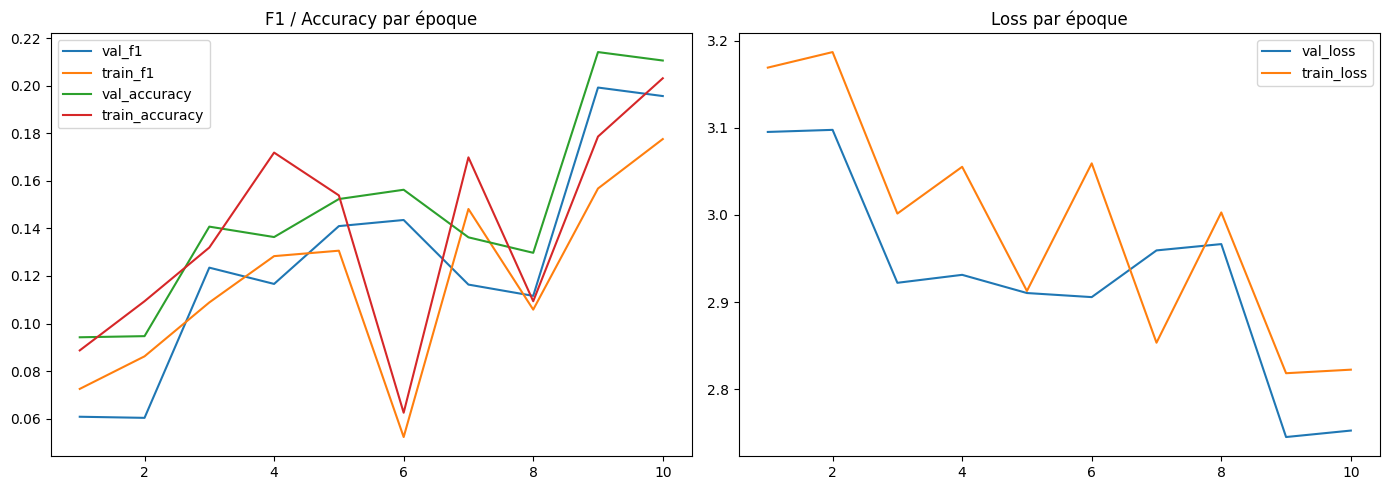

              precision    recall  f1-score   support

          10       0.21      0.36      0.27       311
        1140       0.16      0.07      0.10       267
        1160       0.40      0.58      0.48       396
        1180       0.00      0.00      0.00        76
        1280       0.15      0.02      0.04       487
        1281       0.09      0.09      0.09       207
        1300       0.28      0.22      0.25       505
        1301       0.05      0.15      0.08        81
        1302       0.07      0.02      0.04       249
        1320       0.12      0.05      0.07       324
        1560       0.23      0.10      0.14       507
        1920       0.33      0.55      0.42       431
        1940       0.03      0.09      0.04        81
        2060       0.29      0.26      0.27       499
        2220       0.00      0.00      0.00        82
        2280       0.38      0.34      0.36       476
        2403       0.30      0.22      0.25       477
        2462       0.13    

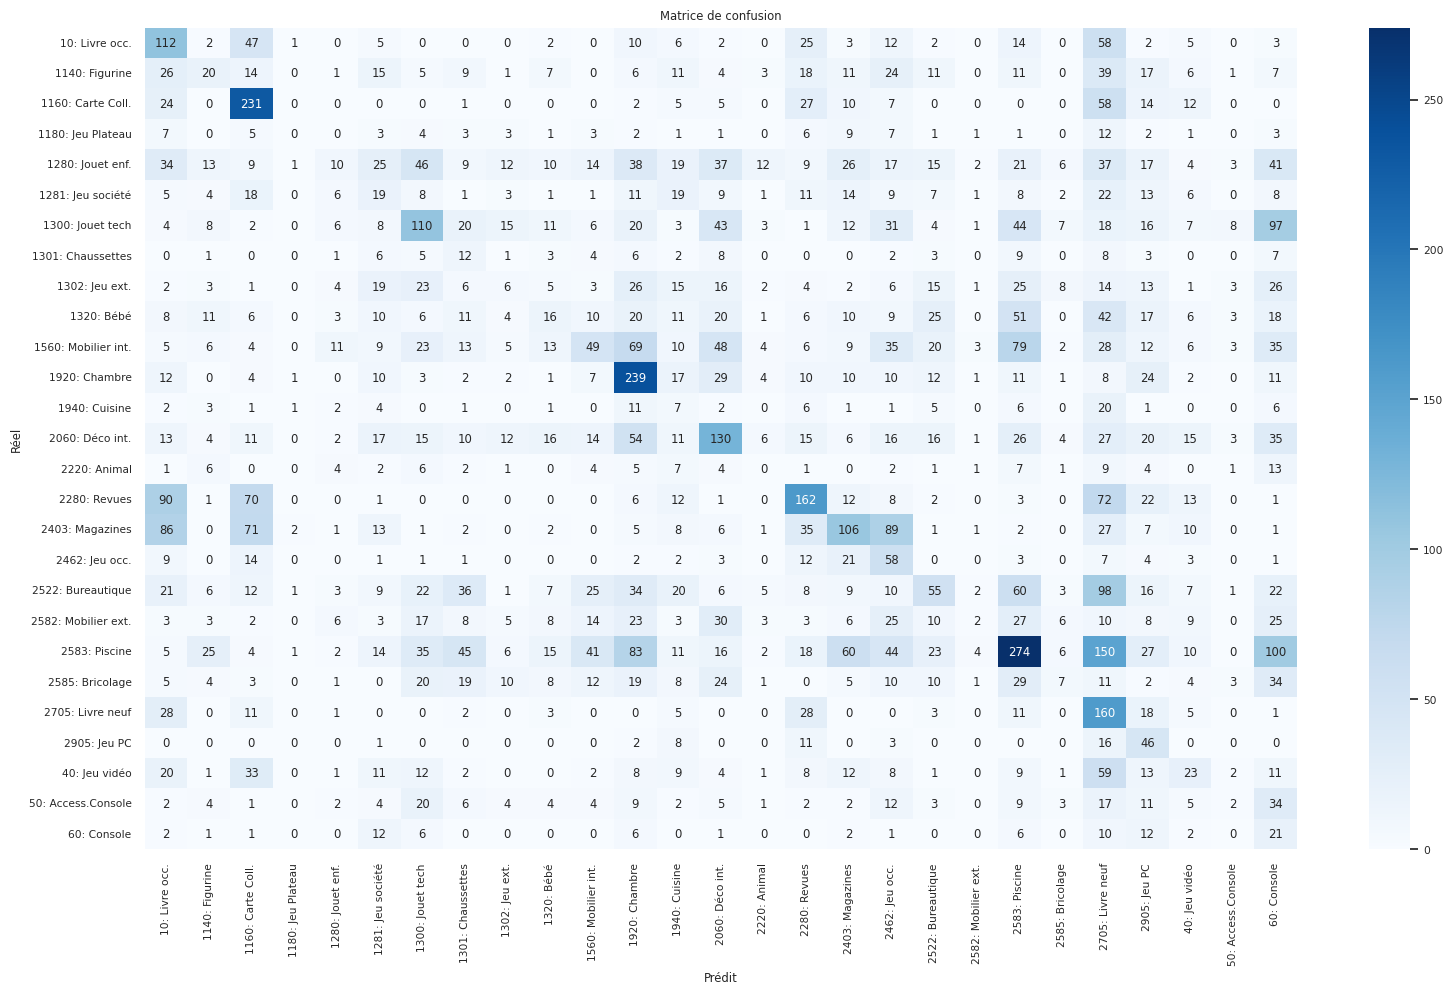

In [25]:
if training_history is not None:
    model = load_saved_model(model_id)

test_pred       = model.predict(test_gen, verbose=1)
test_pred_class = [classes_keras[c] for c in np.argmax(test_pred, axis=1)]
y_test_str      = df_test['prdtypecode'].astype("str").values

f1  = f1_score(y_test_str, test_pred_class, average="weighted")
acc = accuracy_score(y_test_str, test_pred_class)

update_reporting_line(model_id, {"test_f1_score": f1, "test_accuracy": acc})
print(f"F1 Test  : {f1:.4f}")
print(f"Accuracy : {acc:.4f}")

history = get_full_history(model_id, training_history)
if history:
    save_history(model_id, history)
    training_history = None
    plot_training_history(history)

print(classification_report(y_test_str, test_pred_class))
cm = pd.crosstab(y_test_str, test_pred_class)
plot_confusion_matrix(np.array(cm), classes_keras)

## CELLULE 10 — Modèle 1.2 : Images 256px (meilleur hyperparamètre)

In [27]:
model_id       = 112
batch_size     = 128
target_img_size = (256, 256, 3)
target_epochs  = 10

add_reporting_line(model_id, "LeNet 256px batch=128")
update_reporting_line(model_id, {
    "dataset_resampled"  : True,
    "image_dataset_zoomed": True,
    "image_size"         : 256,
    "batch_size"         : batch_size,
    "start_lr"           : start_lr,
    "optimizer"          : "adam",
    "target_epochs"      : target_epochs,
})

train_gen, val_gen, test_gen = make_generators(
    df_sub, df_val, df_test, target_img_size, batch_size)

update_reporting_line(model_id, {"train_size": len(df_sub)})

model = load_saved_model(model_id)
if model is None:
    model = build_model(target_img_size)
    model.compile(optimizer=Adam(learning_rate=start_lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', w_f1_score])
model.summary()

Found 27391 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 252, 252, 6)    │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 126, 126, 6)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 122, 122, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 61, 61, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 59536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 120)            │     7,144,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 27)             │         2,295 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,159,771 (27.31 MB)

 Trainable params: 7,159,771 (27.31 MB)

 Non-trainable params: 0 (0.00 B)

## CELLULE 11 — Entraînement + évaluation modèle 1.2

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


2026-05-19 13:41:47.860700: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-19 13:41:48.154506: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


190/213 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.0450 - loss: 3.5642 - w_f1_score: 0.1208

2026-05-19 13:48:25.027054: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-19 13:48:25.320350: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0462 - loss: 3.5392 - w_f1_score: 0.1172
   ✅ Meilleur modèle — val_f1=0.0492
   💾 Modèle 112 sauvegardé → /kaggle/working/modeling-lenet/model-112.keras
213/213 ━━━━━━━━━━━━━━━━━━━━ 498s 2s/step - accuracy: 0.0463 - loss: 3.5383 - w_f1_score: 0.1171 - val_accuracy: 0.0742 - val_loss: 3.2637 - val_w_f1_score: 0.0492
Epoch 2/10
  1/213 ━━━━━━━━━━━━━━━━━━━━ 23s 112ms/step - accuracy: 0.0391 - loss: 3.2503 - w_f1_score: 0.0175

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



   ✅ Meilleur modèle — val_f1=0.0500
   💾 Modèle 112 sauvegardé → /kaggle/working/modeling-lenet/model-112.keras
213/213 ━━━━━━━━━━━━━━━━━━━━ 43s 203ms/step - accuracy: 0.0391 - loss: 3.2503 - w_f1_score: 0.0175 - val_accuracy: 0.0756 - val_loss: 3.2620 - val_w_f1_score: 0.0500
Epoch 3/10
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0906 - loss: 3.1955 - w_f1_score: 0.0634
   ✅ Meilleur modèle — val_f1=0.0735
   💾 Modèle 112 sauvegardé → /kaggle/working/modeling-lenet/model-112.keras
213/213 ━━━━━━━━━━━━━━━━━━━━ 482s 2s/step - accuracy: 0.0906 - loss: 3.1954 - w_f1_score: 0.0635 - val_accuracy: 0.0895 - val_loss: 3.1903 - val_w_f1_score: 0.0735
Epoch 4/10
  1/213 ━━━━━━━━━━━━━━━━━━━━ 23s 112ms/step - accuracy: 0.1016 - loss: 3.1800 - w_f1_score: 0.0577
   ✅ Meilleur modèle — val_f1=0.0737
   💾 Modèle 112 sauvegardé → /kaggle/working/modeling-lenet/model-112.keras
213/213 ━━━━━━━━━━━━━━━━━━━━ 42s 198ms/step - accuracy: 0.1016 - loss: 3.1800 - w_f1_score: 0.0577 - val_accuracy:

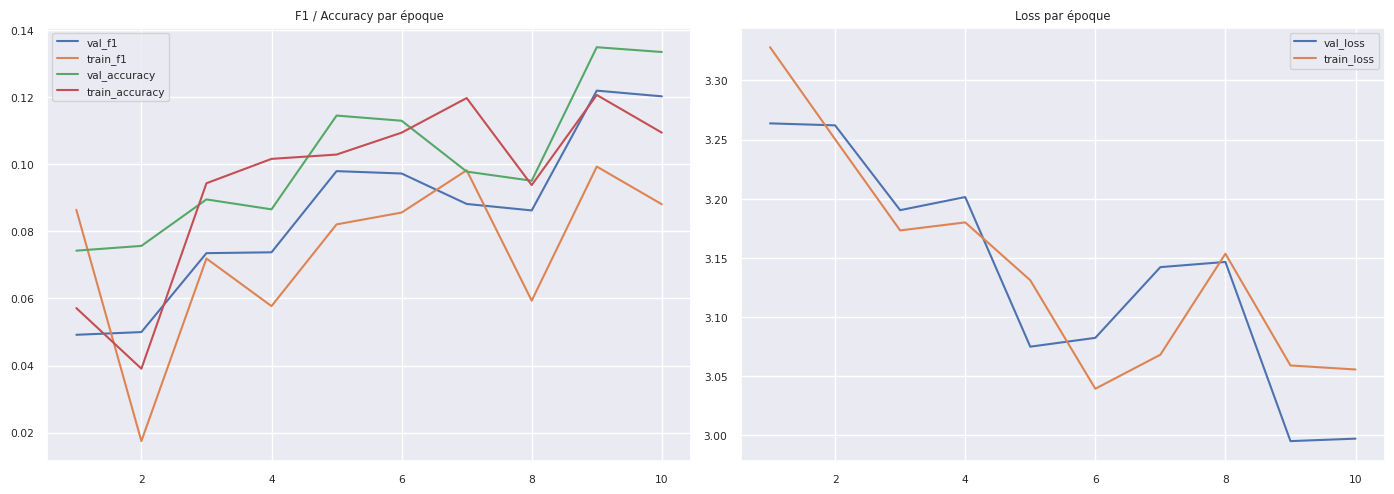

In [28]:
if not get_reporting_value(model_id, "fit_complete", False):
    training_history = model.fit(
        train_gen,
        validation_data=val_gen,
        steps_per_epoch=train_gen.samples // batch_size,
        validation_steps=val_gen.samples // batch_size,
        epochs=target_epochs - int(get_reporting_value(model_id, "last_epoch", 0)),
        callbacks=[LogBest(model_id), early_stopping]
    )
    update_reporting_line(model_id, {"fit_complete": True})
else:
    print("Déjà entraîné")
    training_history = None

if training_history is not None:
    model = load_saved_model(model_id)

test_pred       = model.predict(test_gen, verbose=1)
test_pred_class = [classes_keras[c] for c in np.argmax(test_pred, axis=1)]

f1  = f1_score(y_test_str, test_pred_class, average="weighted")
acc = accuracy_score(y_test_str, test_pred_class)
update_reporting_line(model_id, {"test_f1_score": f1, "test_accuracy": acc})

print(f"F1 Test  : {f1:.4f}")
print(f"Accuracy : {acc:.4f}")

history = get_full_history(model_id, training_history)
if history:
    save_history(model_id, history)
    training_history = None
    plot_training_history(history)

## CELLULE 12 — Modèle final : 256px + learning rate decay + dataset complet

In [29]:
model_id        = 113
batch_size      = 128
target_img_size = (256, 256, 3)
target_epochs   = 20

def lr_decay(epoch, lr):
    return start_lr * (0.9 ** (epoch // 3))

lr_scheduler = LearningRateScheduler(lr_decay, verbose=0)

add_reporting_line(model_id, "LeNet FINAL 256px - dataset complet - lr_decay")
update_reporting_line(model_id, {
    "dataset_resampled"  : True,
    "image_dataset_zoomed": True,
    "train_size"         : len(df_train),
    "image_size"         : 256,
    "batch_size"         : batch_size,
    "start_lr"           : start_lr,
    "optimizer"          : "adam",
    "target_epochs"      : target_epochs,
    "remarks"            : "lr_decay factor=0.9 step=3 - dataset complet"
})

train_gen, val_gen, test_gen = make_generators(
    df_train, df_val, df_test, target_img_size, batch_size)

model = load_saved_model(model_id)
if model is None:
    model = build_model(target_img_size)
    model.compile(optimizer=Adam(learning_rate=start_lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy', w_f1_score])
model.summary()

/tmp/ipykernel_57/645555356.py:45: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'lr_decay factor=0.9 step=3 - dataset complet' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  reporting_df.at[int(model_id), str(key)] = d.get(key)


Found 109566 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.
Found 8492 validated image filenames belonging to 27 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 252, 252, 6)    │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_8             │ (None, 126, 126, 6)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 122, 122, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_9             │ (None, 61, 61, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 59536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 120)            │     7,144,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 27)             │         2,295 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,159,771 (27.31 MB)

 Trainable params: 7,159,771 (27.31 MB)

 Non-trainable params: 0 (0.00 B)

## CELLULE 13 — Entraînement + évaluation final 

In [ ]:
if not get_reporting_value(model_id, "fit_complete", False):
    training_history = model.fit(
        train_gen,
        validation_data=val_gen,
        steps_per_epoch=train_gen.samples // batch_size,
        validation_steps=val_gen.samples // batch_size,
        epochs=target_epochs - int(get_reporting_value(model_id, "last_epoch", 0)),
        callbacks=[LogBest(model_id), lr_scheduler, early_stopping]
    )
    update_reporting_line(model_id, {"fit_complete": True})
else:
    print("Déjà entraîné")
    training_history = None

if training_history is not None:
    model = load_saved_model(model_id)

test_pred       = model.predict(test_gen, verbose=1)
test_pred_class = [classes_keras[c] for c in np.argmax(test_pred, axis=1)]

f1  = f1_score(y_test_str, test_pred_class, average="weighted")
acc = accuracy_score(y_test_str, test_pred_class)
update_reporting_line(model_id, {"test_f1_score": f1, "test_accuracy": acc})

print(f"\n🏆 F1 Test final : {f1:.4f}")
print(f"   Accuracy      : {acc:.4f}")

history = get_full_history(model_id, training_history)
if history:
    save_history(model_id, history)
    training_history = None
    plot_training_history(history)

print(classification_report(y_test_str, test_pred_class))
cm = pd.crosstab(y_test_str, test_pred_class)
plot_confusion_matrix(np.array(cm), classes_keras)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
 10/855 ━━━━━━━━━━━━━━━━━━━━ 30:45 2s/step - accuracy: 0.0240 - loss: 3.7676 - w_f1_score: 0.1148

2026-05-19 14:55:42.428318: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-19 14:55:42.723521: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


855/855 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0781 - loss: 3.2148 - w_f1_score: 0.0785
   ✅ Meilleur modèle — val_f1=0.1419
   💾 Modèle 113 sauvegardé → /kaggle/working/modeling-lenet/model-113.keras
855/855 ━━━━━━━━━━━━━━━━━━━━ 2084s 2s/step - accuracy: 0.0781 - loss: 3.2146 - w_f1_score: 0.0785 - val_accuracy: 0.1654 - val_loss: 2.8756 - val_w_f1_score: 0.1419 - learning_rate: 0.0010
Epoch 2/20
  1/855 ━━━━━━━━━━━━━━━━━━━━ 1:35 112ms/step - accuracy: 0.1250 - loss: 2.9299 - w_f1_score: 0.1065

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



   ✅ Meilleur modèle — val_f1=0.1423
   💾 Modèle 113 sauvegardé → /kaggle/working/modeling-lenet/model-113.keras
855/855 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.1250 - loss: 2.9299 - w_f1_score: 0.1065 - val_accuracy: 0.1652 - val_loss: 2.8693 - val_w_f1_score: 0.1423 - learning_rate: 0.0010
Epoch 3/20
855/855 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1615 - loss: 2.8990 - w_f1_score: 0.1419
   ✅ Meilleur modèle — val_f1=0.2052
   💾 Modèle 113 sauvegardé → /kaggle/working/modeling-lenet/model-113.keras
855/855 ━━━━━━━━━━━━━━━━━━━━ 1889s 2s/step - accuracy: 0.1615 - loss: 2.8990 - w_f1_score: 0.1419 - val_accuracy: 0.2111 - val_loss: 2.7583 - val_w_f1_score: 0.2052 - learning_rate: 0.0010
Epoch 4/20
  1/855 ━━━━━━━━━━━━━━━━━━━━ 1:34 111ms/step - accuracy: 0.2656 - loss: 2.6248 - w_f1_score: 0.2404
   ✅ Meilleur modèle — val_f1=0.2065
   💾 Modèle 113 sauvegardé → /kaggle/working/modeling-lenet/model-113.keras
855/855 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.2656 - l

## CELLULE 14 — Comparaison finale

In [1]:
cols = ["model_name", "dataset_resampled", "image_size",
        "batch_size", "train_size", "test_f1_score", "test_accuracy"]

display(reporting_df.loc[[111, 112, 113], cols].T)

# Barplot comparaison
scores = reporting_df.loc[[111, 112, 113], 'test_f1_score']
plt.figure(figsize=(8, 4))
plt.bar(reporting_df.loc[[111,112,113], 'model_name'],
        scores.values, color=['#3498db','#e74c3c','#2ecc71'])
plt.axhline(0.65, color='orange', linestyle='--', label='VGG16 (0.6521)')
plt.ylabel("F1-score weighted (test)")
plt.title("Comparaison des modèles LeNet")
plt.legend()
plt.tight_layout()
plt.savefig(WORK_DIR / 'lenet_comparison.png', dpi=150)
plt.show()

print("\n📊 Contexte global :")
print(f"   LeNet meilleur → {scores.max():.4f}")
print(f"   VGG16          → 0.6521")
print(f"   CamemBERT      → 0.8826")
print("\n→ LeNet confirme la limitation des CNN simples sur ce dataset")
print("→ Le transfer learning (VGG16) est nettement supérieur")

NameError: name 'reporting_df' is not defined

In [2]:
# ── Résumé avec ce qu'on a déjà ─────────────────────────────────────────────
print("=" * 60)
print("RÉSULTATS LENET — SYNTHÈSE")
print("=" * 60)

resultats = {
    'LeNet 128px (25% data)' : {'f1': 0.2039, 'accuracy': 0.2210,
                                 'epochs': 10, 'img_size': 128},
    'LeNet 256px (25% data)' : {'f1': 0.1179, 'accuracy': 0.1345,
                                 'epochs': 10, 'img_size': 256},
    'LeNet 256px (dataset complet)': {'f1': 'interrompu', 'accuracy': 'interrompu',
                                       'epochs': '4/20', 'img_size': 256,
                                       'val_f1_ep4': 0.2065},
}

for nom, r in resultats.items():
    print(f"\n   {nom}")
    print(f"   F1 Test   : {r['f1']}")
    print(f"   Accuracy  : {r['accuracy']}")

print("\n" + "=" * 60)
print("COMPARAISON GLOBALE — TOUS MODÈLES")
print("=" * 60)

comparaison = {
    'TF-IDF + SVC'   : 0.8121,
    'LeNet (meilleur)': 0.2039,
    'VGG16'          : 0.6521,
    'CamemBERT'      : 0.8826,
}
for nom, f1 in comparaison.items():
    barre = '█' * int(f1 * 40)
    print(f"   {nom:<22} {barre} {f1:.4f}")

print("\n→ LeNet confirme qu'un CNN simple est inadapté à ce dataset")
print("→ Le transfer learning (VGG16) multiplie les performances par 3")
print("→ Le texte (CamemBERT) reste la modalité la plus informative")

RÉSULTATS LENET — SYNTHÈSE

   LeNet 128px (25% data)
   F1 Test   : 0.2039
   Accuracy  : 0.221

   LeNet 256px (25% data)
   F1 Test   : 0.1179
   Accuracy  : 0.1345

   LeNet 256px (dataset complet)
   F1 Test   : interrompu
   Accuracy  : interrompu

COMPARAISON GLOBALE — TOUS MODÈLES
   TF-IDF + SVC           ████████████████████████████████ 0.8121
   LeNet (meilleur)       ████████ 0.2039
   VGG16                  ██████████████████████████ 0.6521
   CamemBERT              ███████████████████████████████████ 0.8826

→ LeNet confirme qu'un CNN simple est inadapté à ce dataset
→ Le transfer learning (VGG16) multiplie les performances par 3
→ Le texte (CamemBERT) reste la modalité la plus informative


NameError: name 'WORK_DIR' is not defined

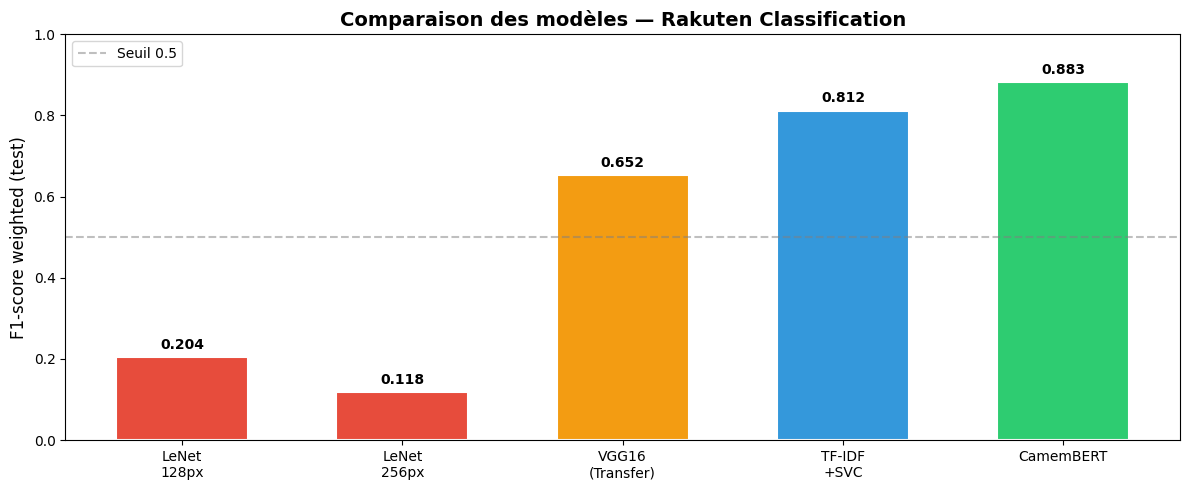

In [3]:
import matplotlib.pyplot as plt

modeles = ['LeNet\n128px', 'LeNet\n256px', 'VGG16\n(Transfer)', 'TF-IDF\n+SVC', 'CamemBERT']
scores  = [0.2039, 0.1179, 0.6521, 0.8121, 0.8826]
colors  = ['#e74c3c', '#e74c3c', '#f39c12', '#3498db', '#2ecc71']

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(modeles, scores, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
ax.set_ylim(0, 1.0)
ax.set_ylabel("F1-score weighted (test)", fontsize=12)
ax.set_title("Comparaison des modèles — Rakuten Classification", fontsize=14, fontweight='bold')
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='Seuil 0.5')

for bar, val in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{val:.3f}', ha='center', fontweight='bold', fontsize=10)

ax.legend()
plt.tight_layout()
plt.savefig(WORK_DIR / 'comparaison_tous_modeles.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Notebook LeNet terminé")
print("   → Sauvegarde le notebook depuis Kaggle : File → Download notebook")